# piControl: decadal storylines of every variable

Step 2 of 2 of the data preparation, plus the storyline figures of every variable. Reads no raw CESM2 output: everything comes from the annual anomalies of `01_piControl_annual_anomalies.ipynb` (step 1).

**Steps**

1. the 1100 annual anomalies (years 101–1200) are cut into 110 non-overlapping decades; each decade becomes one sample (`member`), its year is the centre of the decade,
2. the decades are classified on PDV and AMV (decade means of the annual indices): neutral class inside the 20 % Mahalanobis ellipse, four storylines divided along the axes of maximal variance (`classify_and_plot`),
3. the classes are attached to the decade means of every variable,
4. per variable: composite (mean over the decades of a storyline) with stippling where the t-test across the decades is significant after FDR correction (α = 0.10).

| file | content |
|---|---|
| `ivs_SST.nc` | PDV, AMV and storyline class (IVS) of every decade |
| `decadal/<name>.nc` | decade means of one variable, with PDV, AMV, IVS |

Classes: 0 = neutral, 1 = PDV+/AMV+, 2 = PDV−/AMV+, 3 = PDV−/AMV−, 4 = PDV+/AMV−. PDV on the x axis, AMV on the y axis.

**Names:** in the files and in the code the cloud levels keep the CAM names `CLDLOW`, `CLDMED`, `CLDHGH` (the other notebooks load them by these names); figures and printed output call them LCC, MCC and HCC (low, mid-level and high cloud cover).

A file that is already there is kept (`overwrite = False`).

In [1]:
import pathlib
import warnings

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt

import functions as fv
from functions import (
    read_anom,
    to_decades,
    decades_to_members,
    attach_index,
    classify_and_plot,
    add_ivs,
    save_ivs_index,
    load_ivs_index,
    save_decadal,
    fdr_sig_masks,
    composite_means,
    global_mean_labels,
    plot_ivs_2x2,
    area_weights,
    IVS_labels,
)

# t-test at grid points without data (SST over land, LTS where 700 hPa is below ground)
# -> scipy warns once per storyline and returns NaN there; harmless
warnings.filterwarnings('ignore', message='.*too small.*')
warnings.filterwarnings('ignore', category=RuntimeWarning, module='scipy')

## Config

In [ ]:
# input: annual anomalies <name>_annual_anom.nc and PDV_AMV_annual.nc (01_piControl_annual_anomalies.ipynb)
anom_dir = pathlib.Path('/path/to/data')  # change to your data directory
# output: ivs_SST.nc and decadal/<name>.nc (the analysis and figure notebooks read them from here)
out_dir = pathlib.Path('/path/to/data/piControl')  # change to your output directory

# False: a file that is already there is kept; True: built again and overwritten
overwrite = False

# classification, as in the thesis
decade_years = 10
alpha = 20                 # size of the neutral class in %
classify = 'transformed'   # dividing lines along the axes of maximal variance
ellipse_levels = (0.2,)    # ellipse drawn in the figure (= neutral class)

# composites: FDR level of the stippling, maps cropped to 60°S-60°N
alpha_fdr = 0.10
lat_limit = 60
save_figures = False       # True writes every figure to fv.figure_path(<name>)

# per variable: colour levels, colour map, colour bar label. The scale check above each map
# prints the 99th percentile and the maximum of |anomaly|, so the levels can be set from that.
# Colour maps as in the thesis figures: RdBu_r for K, BrBG for clouds, bwr for radiation.
styles = {
    'SST':    (np.linspace(-0.5, 0.5, 21), 'RdBu_r', 'SST anomaly [K]'),
    'LTS':    (np.linspace(-0.5, 0.5, 21), 'RdBu_r', 'LTS anomaly [K]'),
    'CLDLOW': (np.linspace(-2.0, 2.0, 21), 'BrBG', 'LCC anomaly [%]'),
    'CLDMED': (np.linspace(-2.0, 2.0, 21), 'BrBG', 'MCC anomaly [%]'),
    'CLDHGH': (np.linspace(-2.0, 2.0, 21), 'BrBG', 'HCC anomaly [%]'),
    'TOA':    (np.linspace(-2.5, 2.5, 21), 'bwr', 'net downward TOA anomaly [W m$^{-2}$]'),
    'SWTOA':  (np.linspace(-4.0, 4.0, 21), 'bwr', 'net downward SW anomaly [W m$^{-2}$]'),
    'LWTOA':  (np.linspace(-4.0, 4.0, 21), 'bwr', 'net downward LW anomaly [W m$^{-2}$]'),
}
units = {'SST': 'K', 'LTS': 'K', 'CLDLOW': '%', 'CLDMED': '%', 'CLDHGH': '%',
         'TOA': 'W m-2', 'SWTOA': 'W m-2', 'LWTOA': 'W m-2'}
# names shown in figures and output; files and code keep the CAM names
short = {'CLDLOW': 'LCC', 'CLDMED': 'MCC', 'CLDHGH': 'HCC'}

time_coder = xr.coders.CFDatetimeCoder(use_cftime=True)

## Helpers

In [3]:
index_file = out_dir / 'ivs_SST.nc'


def decadal_file(name):
    return out_dir / 'decadal' / f'{name}.nc'


def needed(path):
    # True if ``path`` has to be written (missing, or overwrite is set)
    return overwrite or not path.exists()


def has_anom(name):
    # TOA is not stored as annual anomaly: it is SWTOA + LWTOA
    parts = ['SWTOA', 'LWTOA'] if name == 'TOA' else [name]
    return all((anom_dir / f'{p}_annual_anom.nc').exists() for p in parts)


def annual(name):
    if name == 'TOA':
        return (read_anom('SWTOA', anom_dir) + read_anom('LWTOA', anom_dir)).rename('TOA')
    return read_anom(name, anom_dir)


def fig_path(name):
    return fv.figure_path(name) if save_figures else None

## What is already computed

In [4]:
names = [name for name in styles if has_anom(name)]
for name in styles:
    state = 'annual anomalies there' if name in names else 'no annual anomalies -> skipped'
    print(f"{short.get(name, name):7s} {state:32s} decadal file {'there' if decadal_file(name).exists() else 'missing'}")
print(f"index   {'there' if index_file.exists() else 'missing'}: {index_file}")

SST     annual anomalies there           decadal file there
LTS     annual anomalies there           decadal file there
LCC     annual anomalies there           decadal file there
MCC     no annual anomalies -> skipped   decadal file missing
HCC     annual anomalies there           decadal file there
TOA     annual anomalies there           decadal file there
SWTOA   annual anomalies there           decadal file there
LWTOA   annual anomalies there           decadal file there
index   there: /Users/liobabraun/Desktop/Uni_Leipzig/MA/server/data/piControl/ivs_SST.nc


## 1 Storyline classification of the decades

PDV and AMV are the decade means of the annual indices (`PDV_AMV_annual.nc`). The classification is done once, here, and only on SST: the storylines are a property of the decades, every other variable gets the same labels.

In [5]:
indices = xr.open_dataset(anom_dir / 'PDV_AMV_annual.nc', decode_times=time_coder).load()
sst = annual('SST')
decades = decades_to_members(to_decades(sst, decade_years), to_decades(indices['PDV'], decade_years),
                             to_decades(indices['AMV'], decade_years), name='SST')
years = decades['year'].values
print(f"{decades.sizes['member']} decades")

110 decades


Classifying data with alpha=20...


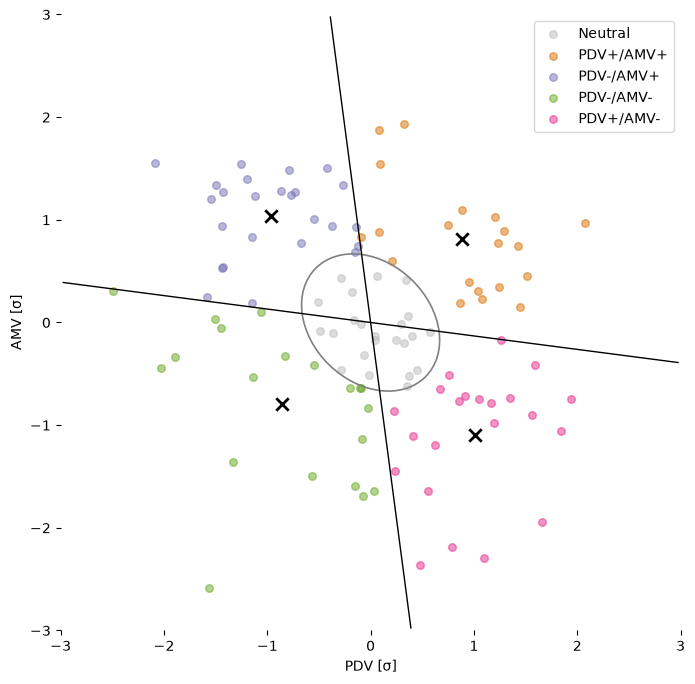

PDV-AMV correlation: r = -0.258
Neutral: 23 points
PDV+/AMV+: 20 points
PDV-/AMV+: 25 points
PDV-/AMV-: 20 points
PDV+/AMV-: 22 points


In [6]:
_, classes, *_ = classify_and_plot(
    pdv_list=[decades['PDV'].values], amv_list=[decades['AMV'].values],
    alpha=alpha, classify=classify, ellipse_levels=ellipse_levels,
    save_path=fig_path('IVS_classification'),
)
decades = add_ivs(decades, classes)

In [7]:
if needed(index_file):
    save_ivs_index(decades, index_file, source='CESM2 piControl ts, ocean only',
                   alpha=alpha, classify=classify, clip_years=100, decade_years=decade_years)
else:
    print(f'{index_file.name}: kept')

# from here on the labels come from the file, so every decadal file carries exactly these
index = load_ivs_index(index_file)
same = np.array_equal(index['IVS'].values, decades['IVS'].values)
print('classes of the file and of this run identical' if same else
      'WARNING: the classes of the file differ from this run - overwrite = True rebuilds it')

ivs_SST.nc: kept
ivs_SST.nc: 110 decades, 105-1195
  source=CESM2 piControl ts, ocean only, alpha=20, classify=transformed, clip_years=100, decade_years=10
classes of the file and of this run identical


Correlation of PDV and AMV over the 110 decades.

In [8]:
pdv, amv = index['PDV'].values, index['AMV'].values
print(f'PDV-AMV correlation r = {np.corrcoef(pdv, amv)[0, 1]:+.3f}')

PDV-AMV correlation r = -0.258


## 2 Decade means of every variable

Annual anomalies → 10-year block means → PDV, AMV and IVS of the index attached (`attach_index` stops if the decades do not line up). TOA = SWTOA + LWTOA, positive downward.

In [9]:
decadal = {}
for name in names:
    path = decadal_file(name)
    if needed(path):
        ds = attach_index(to_decades(annual(name), decade_years), index, name=name).compute()
        save_decadal(ds, path)
    else:
        print(f'{path.name}: kept')
    # the maps below show what is on disk, i.e. what the analysis notebooks read
    decadal[name] = xr.open_dataset(path).load()

SST.nc: kept
LTS.nc: kept
CLDLOW.nc: kept
CLDHGH.nc: kept
TOA.nc: kept
SWTOA.nc: kept
LWTOA.nc: kept


## 3 Storyline composites

Mean over the decades of each storyline; stippled where the one-sample t-test across these decades is significant after FDR correction over all grid points (α_FDR = 0.10, i.e. a global level of 5 %, Wilks 2016). Maps cropped to 60°S–60°N; the values are not.

Scale check above each map: 99th percentile and maximum of |anomaly| over the four composites (global), next to the end of the colour scale. If the percentile is above the end of the scale, the map saturates.

In [10]:
def composites(name):
    levels, cmap, label = styles[name]
    ds = decadal[name]
    means = composite_means(ds)
    sig = fdr_sig_masks(ds[name], ds['IVS'], alpha=alpha_fdr)
    q99 = max(float(abs(m[name]).quantile(0.99)) for m in means.values())
    peak = max(float(abs(m[name]).max()) for m in means.values())
    print(f'{short.get(name, name)}: 99th percentile |anomaly| = {q99:.2f}, maximum {peak:.2f} {units[name]}, '
          f'colour scale reaches ±{levels[-1]:.2f}')
    # radiation: the global mean of each storyline under its panel (large regional
    # anomalies cancel, so the maps alone do not show the energy budget)
    annotate = global_mean_labels(means, name, units[name]) if name in ('TOA', 'SWTOA', 'LWTOA') else None
    plot_ivs_2x2(means, variable=name, levels=levels, cmap=cmap, sig_masks=sig, lat_limit=lat_limit,
                 cbar_label=label, annotate=annotate, save_path=fig_path(f'{name}_composites'))
    plt.show()

### SST

ts over the ocean. The PDV and AMV patterns that define the storylines.

SST: 99th percentile |anomaly| = 0.35, maximum 0.95 K, colour scale reaches ±0.50


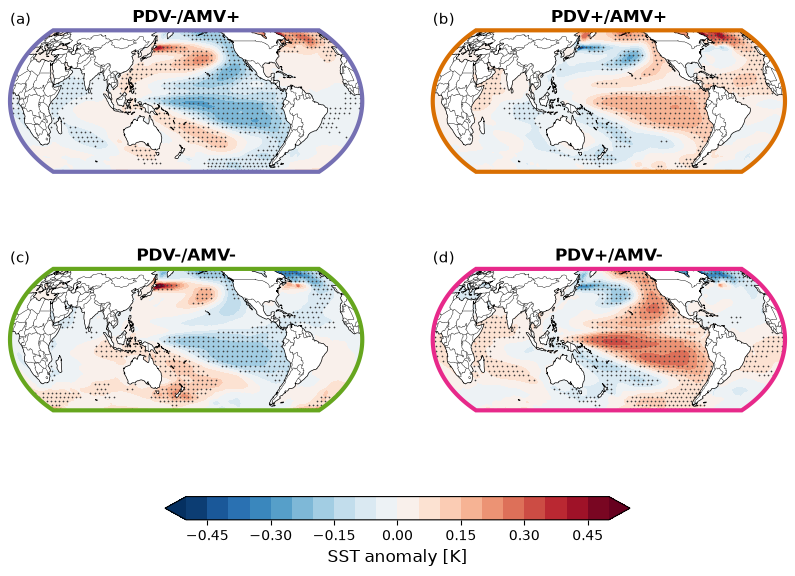

In [11]:
if 'SST' in decadal:
    composites('SST')
else:
    print('SST: no annual anomalies')

### Lower tropospheric stability

LTS = θ(700 hPa) − θ(surface), θ(surface) from `tas` and `ps`. Defined over land too; gaps where 700 hPa is below ground (Antarctic plateau, Himalaya).

LTS: 99th percentile |anomaly| = 0.23, maximum 1.08 K, colour scale reaches ±0.50


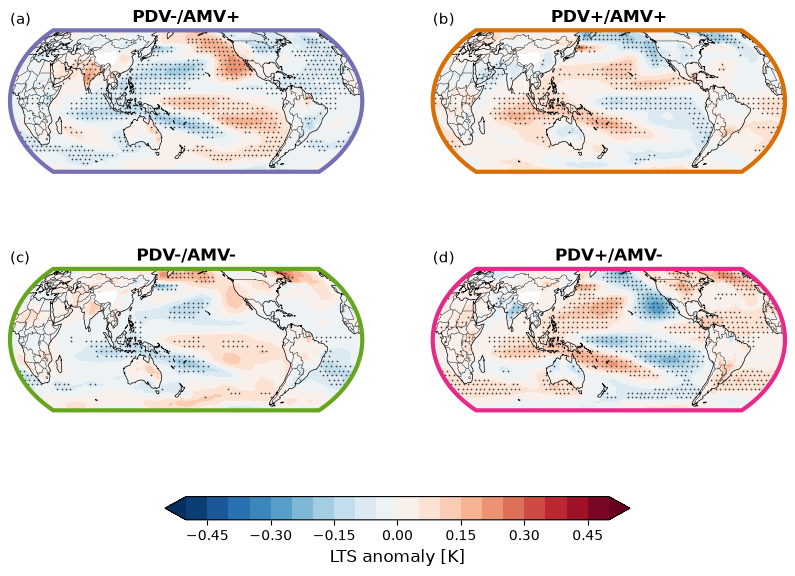

In [12]:
if 'LTS' in decadal:
    composites('LTS')
else:
    print('LTS: no annual anomalies')

### Low cloud cover (LCC)

1200–700 hPa, maximum overlap, in %.

LCC: 99th percentile |anomaly| = 1.70, maximum 31.31 %, colour scale reaches ±2.00


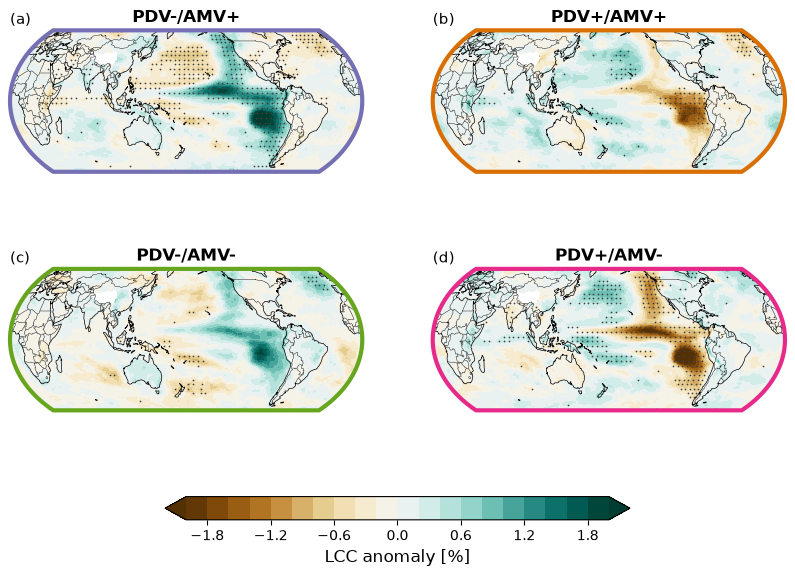

In [13]:
if 'CLDLOW' in decadal:
    composites('CLDLOW')
else:
    print('LCC: no annual anomalies')

### Mid-level cloud cover (MCC)

700–400 hPa, maximum overlap, in %.

In [14]:
if 'CLDMED' in decadal:
    composites('CLDMED')
else:
    print('MCC: no annual anomalies')

MCC: no annual anomalies


### High cloud cover (HCC)

400–50 hPa, maximum overlap, in %.

HCC: 99th percentile |anomaly| = 1.56, maximum 2.04 %, colour scale reaches ±2.00


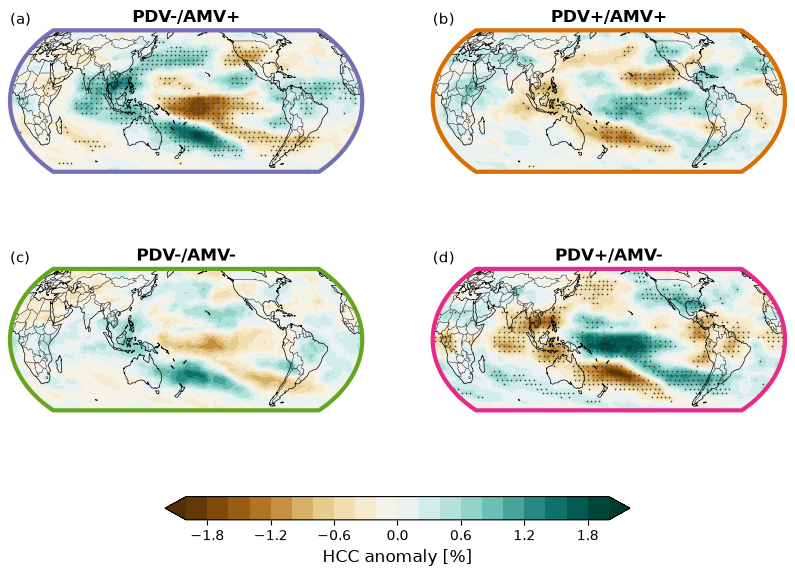

In [15]:
if 'CLDHGH' in decadal:
    composites('CLDHGH')
else:
    print('HCC: no annual anomalies')

### Net TOA radiation

SWTOA + LWTOA, positive downward: Global mean (GMTOA) under each panel.

TOA: 99th percentile |anomaly| = 1.97, maximum 4.02 W m-2, colour scale reaches ±2.50


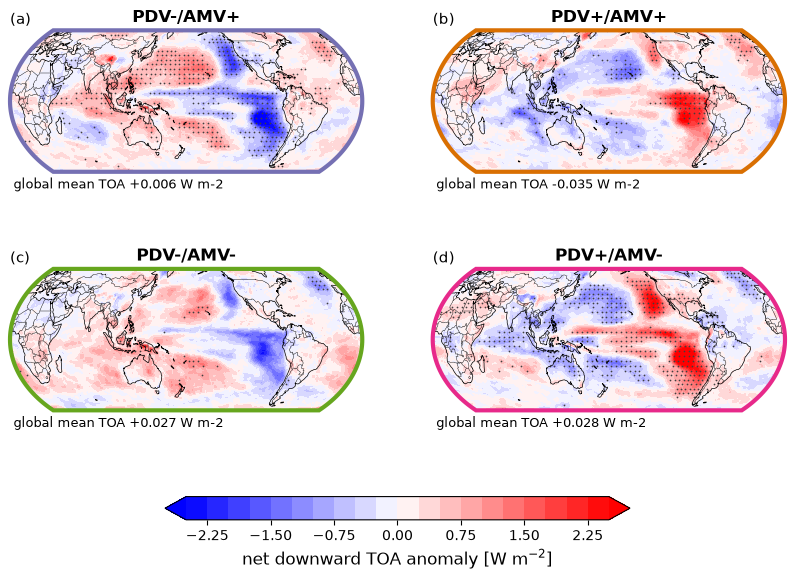

In [16]:
if 'TOA' in decadal:
    composites('TOA')
else:
    print('TOA: no annual anomalies')

### TOA shortwave

`rsdt − rsut`, positive downward

SWTOA: 99th percentile |anomaly| = 2.98, maximum 6.45 W m-2, colour scale reaches ±4.00


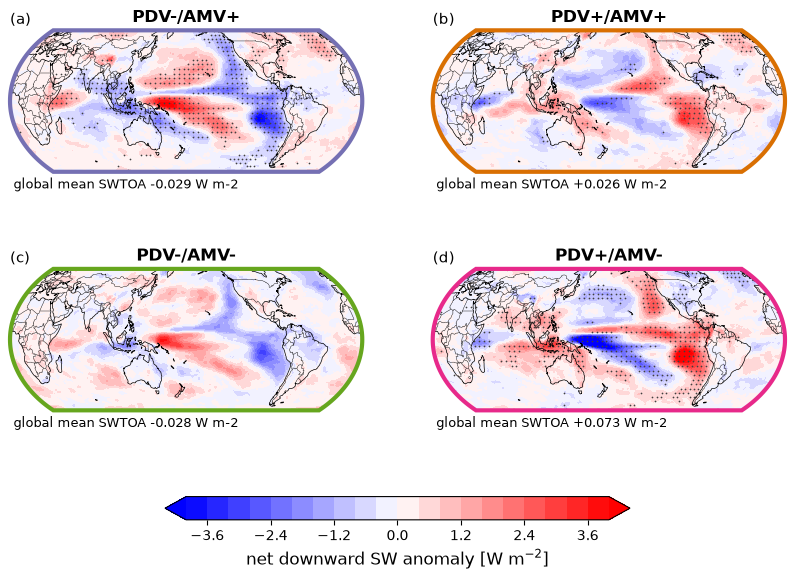

In [17]:
if 'SWTOA' in decadal:
    composites('SWTOA')
else:
    print('SWTOA: no annual anomalies')

### TOA longwave

`−rlut`, positive downward

LWTOA: 99th percentile |anomaly| = 2.51, maximum 5.35 W m-2, colour scale reaches ±4.00


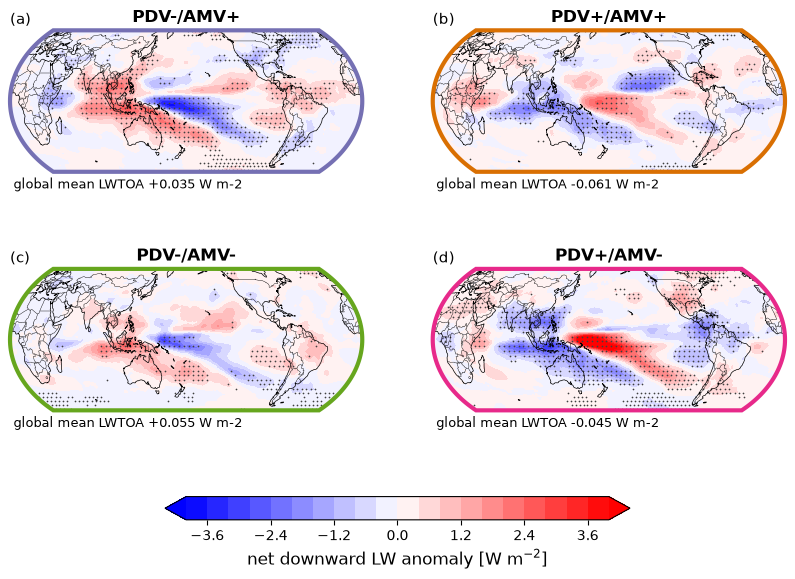

In [18]:
if 'LWTOA' in decadal:
    composites('LWTOA')
else:
    print('LWTOA: no annual anomalies')